# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name:** Sania  
**Student ID:** _023-24-0277_  
**Section:** _H_  
**GitHub:** _https://github.com/saniamirani_  
**Kaggle:** _https://www.kaggle.com/saniam58_  
**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment

**Dataset Sources:**
- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

This notebook implements the required Week 7 workflow: clean → vectorize → train Multinomial Naive Bayes → evaluate → interpret → compare.


---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
TEST_SIZE = 0.20


def metric_dict(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }

def print_metrics(title, metrics):
    print(title)
    for name, value in metrics.items():
        print(f"{name}: {value:.4f}")


---

## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [ ]:
# Task 1 — load spam.csv, inspect shape/head/class balance
df_spam = pd.read_csv("spam.csv", encoding="latin-1")

cols_to_drop = [col for col in df_spam.columns if 'Unnamed' in col]
df_spam = df_spam.drop(columns=cols_to_drop)

df_spam = df_spam.rename(columns={'v1': 'label', 'v2': 'message'})

print(df_spam.shape)
print(df_spam.head())
print(f"\n{df_spam['label'].value_counts()}\n")
print((df_spam['label'].value_counts(normalize=True) * 100).round(1))

(5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

label
ham     4825
spam     747
Name: count, dtype: int64

label
ham     86.6
spam    13.4
Name: proportion, dtype: float64


In [ ]:
# Task 1 (continued) — load Tweets.csv, drop neutral, inspect shape/head/class balance
tweets_df = pd.read_csv("Tweets.csv")


tweets_df = tweets_df[tweets_df['airline_sentiment']!='neutral']
tweets_df = tweets_df.dropna(subset=["airline_sentiment", "text"])

tweet_balance = tweets_df["airline_sentiment"].value_counts()
tweet_percent = tweets_df["airline_sentiment"].value_counts(normalize=True).mul(100)


print("Rows after dropping neutral:", len(tweets_df))
display(tweets_df[["airline_sentiment", "text"]].head())
print("\nClass balance after keeping positive/negative only:")
display(pd.DataFrame({"Count": tweet_balance, "Percentage": tweet_percent.round(2)}))
print("\nA row represents one airline-related tweet with a positive or negative sentiment label.")


Rows after dropping neutral: 11541


,airline_sentiment,text
1,positive,@VirginAmerica plus you've added commercials t...
3,negative,@VirginAmerica it's really aggressive to blast...
4,negative,@VirginAmerica and it's a really big bad thing...
5,negative,@VirginAmerica seriously would pay $30 a fligh...
6,positive,"@VirginAmerica yes, nearly every time I fly VX..."



Class balance after keeping positive/negative only:


,Count,Percentage
airline_sentiment,,
negative,9178,79.53
positive,2363,20.47



A row represents one airline-related tweet with a positive or negative sentiment label.


**Answer 2 — Task A (Spam):**  
_The dataset has 5572 rows and each rows represents single mobile text message._

**Answer 2 — Task B (Sentiment):**  
_The dataset has 11541 rows and each row represents single scraped tweet regarding major US airline._

---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [ ]:
df_spam["clean_message"]=df_spam["message"].str.lower()

df_spam["clean_message"] = df_spam["clean_message"].str.strip()
df_spam["clean_message"] = df_spam["clean_message"].str.replace(r"\s+", " ", regex=True)

df_spam["clean_message"] = df_spam["clean_message"].str.replace(r"[^\w\s]", "", regex=True)


print("Example before/after cleaning:")
display(df_spam[["message", "clean_message"]].head())


Example before/after cleaning:


,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...


In [ ]:
spam_label_map = {"ham": 0, "spam": 1}
X_spam = spam_df["clean_message"]
y_spam = spam_df["label"].map(spam_label_map)

X_spam_train, X_spam_test, y_spam_train, y_spam_test = train_test_split(
    X_spam, y_spam,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_spam
)

spam_vectorizer = TfidfVectorizer(
    lowercase=False,
    stop_words=None,
    ngram_range=(1, 1)
)

X_spam_train_vec = spam_vectorizer.fit_transform(X_spam_train)
X_spam_test_vec = spam_vectorizer.transform(X_spam_test)

print("Training rows:", X_spam_train_vec.shape[0])
print("Test rows:", X_spam_test_vec.shape[0])
print("Vocabulary size:", len(spam_vectorizer.get_feature_names_out()))


Training rows: 4457
Test rows: 1115
Vocabulary size: 7658


**Answer 4 — Why fit on training data only:**  
The vectorizer is fitted only on the training messages so that the vocabulary and TF-IDF statistics are learned without using information from the test set. Fitting on the full dataset before splitting would cause data leakage and could make the test performance look better than it really is.


---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

Task A — Multinomial Naive Bayes
Accuracy: 0.9605
Precision: 1.0000
Recall: 0.7047
F1-score: 0.8268


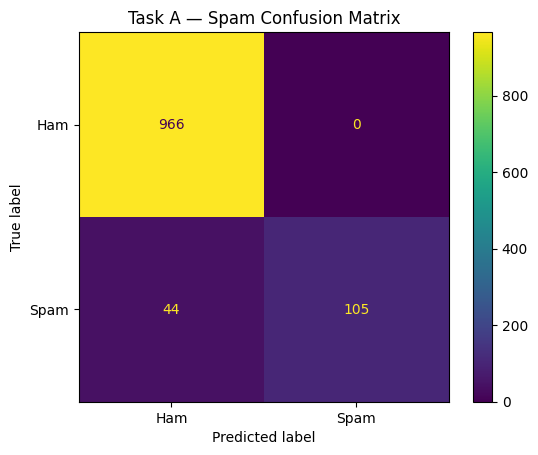

True negatives (ham correctly classified): 966
False positives (ham classified as spam): 0
False negatives (spam classified as ham): 44
True positives (spam correctly classified): 105


In [ ]:
spam_nb = MultinomialNB()
spam_nb.fit(X_spam_train_vec, y_spam_train)

y_spam_pred = spam_nb.predict(X_spam_test_vec)
spam_metrics = metric_dict(y_spam_test, y_spam_pred)

print_metrics("Task A — Multinomial Naive Bayes", spam_metrics)

cm_spam = confusion_matrix(y_spam_test, y_spam_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_spam, display_labels=["Ham", "Spam"])
disp.plot()
plt.title("Task A — Spam Confusion Matrix")
plt.show()

tn, fp, fn, tp = cm_spam.ravel()
print(f"True negatives (ham correctly classified): {tn}")
print(f"False positives (ham classified as spam): {fp}")
print(f"False negatives (spam classified as ham): {fn}")
print(f"True positives (spam correctly classified): {tp}")


### Task 5 — Spam Model Metrics

| Metric | Value |
|---|---:|
| Accuracy | {spam_metrics["Accuracy"]:.4f} |
| Precision | {spam_metrics["Precision"]:.4f} |
| Recall | {spam_metrics["Recall"]:.4f} |
| F1-score | {spam_metrics["F1-score"]:.4f} |

**Answer 6:**  
For spam filtering, a false positive means a genuine message may be hidden as spam, while a false negative allows an unwanted spam message into the inbox. In many practical settings, false positives are especially costly because an important genuine message could be missed. Therefore, I would prioritize **precision** when tuning the spam filter, while still monitoring recall so that the filter does not allow too much spam through.


---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [ ]:
feature_names_spam = spam_vectorizer.get_feature_names_out()
log_prob_spam = spam_nb.feature_log_prob_[1]
log_prob_ham = spam_nb.feature_log_prob_[0]

spam_ham_difference = log_prob_spam - log_prob_ham

top_spam_idx = np.argsort(spam_ham_difference)[-15:][::-1]
top_ham_idx = np.argsort(spam_ham_difference)[:15]

top_spam_words = pd.DataFrame({
    "Word": feature_names_spam[top_spam_idx],
    "Spam_vs_Ham_Log_Probability_Difference": spam_ham_difference[top_spam_idx]
})

top_ham_words = pd.DataFrame({
    "Word": feature_names_spam[top_ham_idx],
    "Ham_vs_Spam_Log_Probability_Difference": -spam_ham_difference[top_ham_idx]
})

print("15 words most strongly associated with spam:")
display(top_spam_words)

print("15 words most strongly associated with ham:")
display(top_ham_words)


15 words most strongly associated with spam:


,Word,Spam_vs_Ham_Log_Probability_Difference
0,claim,3.469874
1,prize,3.266109
2,150p,3.003695
3,www,3.000298
4,uk,2.899588
5,tone,2.863985
6,18,2.808092
7,guaranteed,2.787921
8,cs,2.753827
9,1000,2.729885


15 words most strongly associated with ham:


,Word,Ham_vs_Spam_Log_Probability_Difference
0,gt,3.205885
1,lt,3.195171
2,my,3.175798
3,ok,3.140837
4,ll,3.098454
5,later,3.034266
6,lor,2.976343
7,da,2.937991
8,but,2.864343
9,home,2.864283


**Answer 7:**  
The strongest words can be inspected in the two tables above. Spam-associated words should often reflect promotional offers, prizes, money, urgency, or other common spam-message patterns, while ham-associated words are more likely to reflect ordinary personal conversation. The exact words depend on the training/test split and vectorizer, so the tables above are the evidence used for this interpretation.


In [ ]:
my_messages = [
    "Congratulations! You have won a free cash prize. Call now to claim your reward!",
    "Hi, I will meet you at the library after class.",
    "URGENT! You have been selected for a free vacation. Reply now to receive it."
]

my_messages_clean = [clean_basic(msg) for msg in my_messages]
my_messages_vec = spam_vectorizer.transform(my_messages_clean)
my_predictions = spam_nb.predict(my_messages_vec)

prediction_names = {0: "ham", 1: "spam"}
results = pd.DataFrame({
    "Message": my_messages,
    "Predicted Class": [prediction_names[p] for p in my_predictions]
})

display(results)


,Message,Predicted Class
0,Congratulations! You have won a free cash priz...,spam
1,"Hi, I will meet you at the library after class.",ham
2,URGENT! You have been selected for a free vaca...,spam


**Answer 8:**  
The test messages include clearly promotional/urgent messages and an ordinary personal message. The predictions can be compared directly with those expectations in the table above; any unexpected result may occur because the classifier uses learned word patterns rather than human-level understanding of the full message context.


---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**  
_https://www.kaggle.com/code/saniam58/notebook12af8155ef?scriptVersionId=354215671_


---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [ ]:
tweets_df["clean_text"] = tweets_df["text"].apply(clean_tweet)

sentiment_label_map = {"negative": 0, "positive": 1}
X_sentiment = tweets_df["clean_text"]
y_sentiment = tweets_df["airline_sentiment"].map(sentiment_label_map)

X_sent_train, X_sent_test, y_sent_train, y_sent_test = train_test_split(
    X_sentiment, y_sentiment,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_sentiment
)

sentiment_vectorizer = TfidfVectorizer(
    lowercase=False,
    stop_words=None,
    ngram_range=(1, 2),
    min_df=2
)

X_sent_train_vec = sentiment_vectorizer.fit_transform(X_sent_train)
X_sent_test_vec = sentiment_vectorizer.transform(X_sent_test)

print("Training rows:", X_sent_train_vec.shape[0])
print("Test rows:", X_sent_test_vec.shape[0])
print("Vocabulary size:", len(sentiment_vectorizer.get_feature_names_out()))

print("\nExample tweet cleaning:")
display(tweets_df[["text", "clean_text"]].head())


Training rows: 9232
Test rows: 2309
Vocabulary size: 20385

Example tweet cleaning:


,text,clean_text
1,@VirginAmerica plus you've added commercials t...,plus you ve added commercials to the experienc...
3,@VirginAmerica it's really aggressive to blast...,it s really aggressive to blast obnoxious ente...
4,@VirginAmerica and it's a really big bad thing...,and it s a really big bad thing about it
5,@VirginAmerica seriously would pay $30 a fligh...,seriously would pay 30 a flight for seats that...
6,"@VirginAmerica yes, nearly every time I fly VX...",yes nearly every time i fly vx this ear worm w...


**Answer 12:**  
For tweets, I removed URLs and @mentions because they are often identifiers or links rather than useful sentiment words. I kept hashtag words by removing the `#` symbol but preserving the word itself, because a hashtag such as `#great` can contain useful sentiment information.


---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

Task B — Multinomial Naive Bayes
Accuracy: 0.8484
Precision: 0.9920
Recall: 0.2622
F1-score: 0.4147


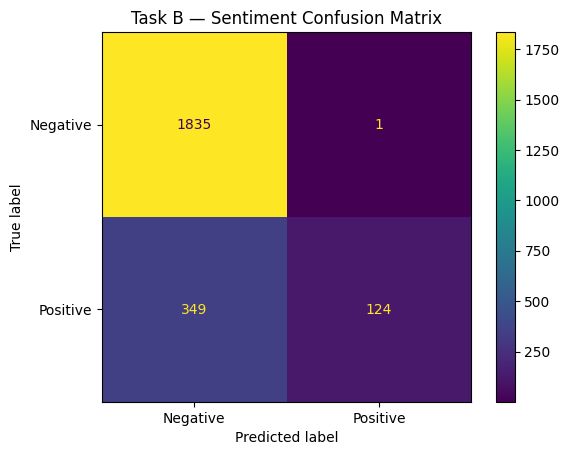

In [ ]:
sentiment_nb = MultinomialNB()
sentiment_nb.fit(X_sent_train_vec, y_sent_train)

y_sent_pred = sentiment_nb.predict(X_sent_test_vec)
sentiment_metrics = metric_dict(y_sent_test, y_sent_pred)

print_metrics("Task B — Multinomial Naive Bayes", sentiment_metrics)

cm_sent = confusion_matrix(y_sent_test, y_sent_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_sent, display_labels=["Negative", "Positive"])
disp.plot()
plt.title("Task B — Sentiment Confusion Matrix")
plt.show()


### Task 13 — Sentiment Model Metrics

| Metric | Value |
|---|---:|
| Accuracy | {sentiment_metrics["Accuracy"]:.4f} |
| Precision | {sentiment_metrics["Precision"]:.4f} |
| Recall | {sentiment_metrics["Recall"]:.4f} |
| F1-score | {sentiment_metrics["F1-score"]:.4f} |

**Answer 14:**  
Task A F1-score: **{spam_metrics["F1-score"]:.4f}**  
Task B F1-score: **{sentiment_metrics["F1-score"]:.4f}**

The task with the higher F1-score performed better on this test split. Spam SMS is usually shorter and more formulaic, so word-level independence can be a reasonable approximation. Tweets contain more context-dependent language, including negation, sarcasm, abbreviations, and multi-word expressions, so the independence assumption can be less realistic. The metric difference above provides the evidence for how strongly that limitation affected these particular results.


---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**  
_Paste your published public Kaggle notebook URL here after completing the Kaggle publication step._


---

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

### Task 17 — Task A vs. Task B (Naive Bayes)

| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---:|---:|
| Accuracy | {spam_metrics["Accuracy"]:.4f} | {sentiment_metrics["Accuracy"]:.4f} |
| Precision | {spam_metrics["Precision"]:.4f} | {sentiment_metrics["Precision"]:.4f} |
| Recall | {spam_metrics["Recall"]:.4f} | {sentiment_metrics["Recall"]:.4f} |
| F1-score | {spam_metrics["F1-score"]:.4f} | {sentiment_metrics["F1-score"]:.4f} |

The table compares the same Multinomial Naive Bayes workflow across the two text-classification problems.


In [ ]:
logreg_spam = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
logreg_spam.fit(X_spam_train_vec, y_spam_train)

y_logreg_pred = logreg_spam.predict(X_spam_test_vec)
logreg_metrics = metric_dict(y_spam_test, y_logreg_pred)

print_metrics("Task A — Logistic Regression", logreg_metrics)

comparison_task_a = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Naive Bayes": [
        spam_metrics["Accuracy"],
        spam_metrics["Precision"],
        spam_metrics["Recall"],
        spam_metrics["F1-score"]
    ],
    "Logistic Regression": [
        logreg_metrics["Accuracy"],
        logreg_metrics["Precision"],
        logreg_metrics["Recall"],
        logreg_metrics["F1-score"]
    ]
})

display(comparison_task_a.style.format({
    "Naive Bayes": "{:.4f}",
    "Logistic Regression": "{:.4f}"
}))

best_model_by_f1 = (
    "Naive Bayes" if spam_metrics["F1-score"] >= logreg_metrics["F1-score"]
    else "Logistic Regression"
)

print(
    f"Based on F1-score on this test split, {best_model_by_f1} has the higher "
    f"F1-score."
)


Task A — Logistic Regression
Accuracy: 0.9722
Precision: 0.9917
Recall: 0.7987
F1-score: 0.8848


,Metric,Naive Bayes,Logistic Regression
0,Accuracy,0.9605,0.9722
1,Precision,1.0000,0.9917
2,Recall,0.7047,0.7987
3,F1-score,0.8268,0.8848


Based on F1-score on this test split, Logistic Regression has the higher F1-score.


### Task 18 — Naive Bayes vs. Logistic Regression (Task A)

| Metric | Naive Bayes | Logistic Regression |
|---|---:|---:|
| Accuracy | {spam_metrics["Accuracy"]:.4f} | {logreg_metrics["Accuracy"]:.4f} |
| Precision | {spam_metrics["Precision"]:.4f} | {logreg_metrics["Precision"]:.4f} |
| Recall | {spam_metrics["Recall"]:.4f} | {logreg_metrics["Recall"]:.4f} |
| F1-score | {spam_metrics["F1-score"]:.4f} | {logreg_metrics["F1-score"]:.4f} |

**Answer 18:**  
Using the F1-score as the comparison metric, the model with the larger F1-score in the table above performed better on this test split. This comparison is useful because both models were trained on the same Task A TF-IDF features. Any difference is therefore related to the learning algorithms and their assumptions rather than a different feature representation.


---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**  
Naive Bayes was evaluated on two different text-classification tasks using the same overall workflow. The Task A and Task B metric tables show how its performance changed between relatively formulaic SMS messages and more context-dependent airline tweets. The word-probability analysis also showed which vocabulary the spam classifier associated most strongly with each class. Comparing Naive Bayes with Logistic Regression on the same Task A features showed how two different classifiers can produce different results from the same representation. The F1-score provides a useful single comparison because it combines precision and recall. One important limitation of the Naive Bayes independence assumption is that words are not truly independent in natural language, especially when meaning depends on phrases, negation, or context. The results therefore demonstrate both the usefulness of Naive Bayes for text classification and the importance of checking its assumptions against the actual data.


---